In [1]:
# ============================================================
# IMPORTS
# ============================================================
import torch
import matplotlib.pyplot as plt
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parents[2]

sys.path.append(str(PROJECT_ROOT))

import torch.nn.functional as F
import numpy as np

from core.fno import FNO3d
from flow.cavity_driven_3d.dataset.dataset import Cavity3DDataset

In [2]:
# ============================================================
# DEVICE
# ============================================================

if torch.backends.mps.is_available():
    device = torch.device("mps")

elif torch.cuda.is_available():
    device = torch.device("cuda")

else:
    device = torch.device("cpu")

print(device)

mps


In [8]:
# ============================================================
# LOAD CHECKPOINT
# ============================================================

checkpoint1 = torch.load(
    "../checkpoints/best_fno.pt",
    map_location=device,
)

checkpoint2 = torch.load(
    "../checkpoints/best_fno_8.pt",
    map_location=device,
)

print("Checkpoint Loaded...")

Checkpoint Loaded...


In [10]:
# ============================================================
# MODEL
# ============================================================

model1 = FNO3d(
    modesx=checkpoint1["modesx"],
    modesy=checkpoint1["modesy"],
    modesz=checkpoint1["modesz"],
    width=checkpoint1["width"],
    in_channels=checkpoint1["in_channels"],
    out_channels=checkpoint1["out_channels"],
    n_layers=2,
).to(device)

model1.load_state_dict(
    checkpoint1["model_state_dict"]
)

model1.eval()


model2 = FNO3d(
    modesx=checkpoint2["modesx"],
    modesy=checkpoint2["modesy"],
    modesz=checkpoint2["modesz"],
    width=checkpoint2["width"],
    in_channels=checkpoint2["in_channels"],
    out_channels=checkpoint2["out_channels"],
    n_layers=8,
).to(device)

model2.load_state_dict(
    checkpoint2["model_state_dict"]
)

model2.eval()

print("Model Loaded...")

Model Loaded...


In [64]:
print(f"Model 1: {model1}")

Model 1: FNO3d(
  (activation): GELU(approximate='none')
  (lift): Conv3d(7, 32, kernel_size=(1, 1, 1), stride=(1, 1, 1))
  (layers): ModuleList(
    (0-1): 2 x ModuleDict(
      (spectral): SpectralConv3d()
      (local): Conv3d(32, 32, kernel_size=(1, 1, 1), stride=(1, 1, 1))
    )
  )
  (project): Sequential(
    (0): Conv3d(32, 128, kernel_size=(1, 1, 1), stride=(1, 1, 1))
    (1): GELU(approximate='none')
    (2): Conv3d(128, 3, kernel_size=(1, 1, 1), stride=(1, 1, 1))
  )
)


In [65]:
print(f"Model 2: {model2}")

Model 2: FNO3d(
  (activation): GELU(approximate='none')
  (lift): Conv3d(7, 32, kernel_size=(1, 1, 1), stride=(1, 1, 1))
  (layers): ModuleList(
    (0-7): 8 x ModuleDict(
      (spectral): SpectralConv3d()
      (local): Conv3d(32, 32, kernel_size=(1, 1, 1), stride=(1, 1, 1))
    )
  )
  (project): Sequential(
    (0): Conv3d(32, 128, kernel_size=(1, 1, 1), stride=(1, 1, 1))
    (1): GELU(approximate='none')
    (2): Conv3d(128, 3, kernel_size=(1, 1, 1), stride=(1, 1, 1))
  )
)


In [11]:
# ============================================================
# DATASET
# ============================================================

dataset = Cavity3DDataset(
    "../data/processed/dataset.pt",
    normalize=True,
)

print("Dataset Loaded...")
print(len(dataset))

Dataset Loaded...
3000


In [38]:
# ============================================================
# SAMPLE
# ============================================================

sample = np.random.randint(len(dataset))

X, Y = dataset[sample]

print(X.shape)
print(Y.shape)

torch.Size([7, 32, 32, 32])
torch.Size([3, 32, 32, 32])


In [39]:
# ============================================================
# INFERENCE
# ============================================================

with torch.no_grad():

    prediction1 = model1(
        X.unsqueeze(0).to(device)
    )

prediction1 = prediction1.squeeze(0).cpu()

print(prediction1.shape)

with torch.no_grad():

    prediction2 = model2(
        X.unsqueeze(0).to(device)
    )

prediction2 = prediction2.squeeze(0).cpu()

print(prediction2.shape)

torch.Size([3, 32, 32, 32])
torch.Size([3, 32, 32, 32])


In [40]:
# ============================================================
# DENORMALIZE
# ============================================================

prediction1 = dataset.denormalize_output(
    prediction1
)[0]

prediction2 = dataset.denormalize_output(
    prediction2
)[0]

ground_truth = dataset.denormalize_output(
    Y
)[0]

In [41]:
print(ground_truth.shape)

torch.Size([3, 32, 32, 32])


In [42]:
# ============================================================
# COMPONENTS
# ============================================================

u_true = ground_truth[0]
v_true = ground_truth[1]
w_true = ground_truth[2]

u_pred1 = prediction1[0]
v_pred1 = prediction1[1]
w_pred1 = prediction1[2]

u_pred2 = prediction2[0]
v_pred2 = prediction2[1]
w_pred2 = prediction2[2]

In [62]:
# ============================================================
# METRICS
# ============================================================

mse1 = F.mse_loss(
    prediction1,
    ground_truth,
)

mae1 = F.l1_loss(
    prediction1,
    ground_truth,
)

relative_l2_1 = (
    torch.norm(prediction1-ground_truth)
    /
    torch.norm(ground_truth)
)

u_mse1 = F.mse_loss(
    u_true,
    u_pred1
)

v_mse1 = F.mse_loss(
    v_true,
    v_pred1
)

w_mse1 = F.mse_loss(
    w_true,
    w_pred1
)
print(f"MODEL 1 METRICS:")
print(f"MSE         : {mse1:.6e}")
print(f"MAE         : {mae1:.6e}")
print(f"Relative L2 : {relative_l2_1:.6e}")
print(f"U MSE       : {u_mse1:.6e}")
print(f"V MSE       : {v_mse1:.6e}")
print(f"W MSE       : {w_mse1:.6e}")
print(f"-"*60)



mse2 = F.mse_loss(
    prediction2,
    ground_truth,
)

mae2 = F.l1_loss(
    prediction2,
    ground_truth,
)

relative_l2_2 = (
    torch.norm(prediction2-ground_truth)
    /
    torch.norm(ground_truth)
)

u_mse2 = F.mse_loss(
    u_true,
    u_pred2
)

v_mse2 = F.mse_loss(
    v_true,
    v_pred2
)

w_mse2 = F.mse_loss(
    w_true,
    w_pred2
)
print(f"MODEL 2 METRICS:")
print(f"MSE         : {mse2:.6e}")
print(f"MAE         : {mae2:.6e}")
print(f"Relative L2 : {relative_l2_2:.6e}")
print(f"U MSE       : {u_mse2:.6e}")
print(f"V MSE       : {v_mse2:.6e}")
print(f"W MSE       : {w_mse2:.6e}")

MODEL 1 METRICS:
MSE         : 1.668411e-03
MAE         : 1.698663e-02
Relative L2 : 3.706926e-01
U MSE       : 4.676791e-03
V MSE       : 3.276964e-04
W MSE       : 7.462112e-07
------------------------------------------------------------
MODEL 2 METRICS:
MSE         : 1.153188e-02
MAE         : 4.839271e-02
Relative L2 : 9.745654e-01
U MSE       : 3.310953e-02
V MSE       : 1.483223e-03
W MSE       : 2.871179e-06


In [66]:
# ============================================================
# MID PLANE
# ============================================================

mid = u_true.shape[2] // 2

u_true_mid = u_true[:, :, mid]
v_true_mid = v_true[:, :, mid]
w_true_mid = w_true[:, :, mid]

u_pred_mid1 = u_pred1[:, :, mid]
v_pred_mid1 = v_pred1[:, :, mid]
w_pred_mid1 = w_pred1[:, :, mid]

u_pred_mid2 = u_pred2[:, :, mid]
v_pred_mid2 = v_pred2[:, :, mid]
w_pred_mid2 = w_pred2[:, :, mid]
print(u_true_mid.shape)

torch.Size([32, 32])


In [ ]:
# ============================================================
# COORDINATES
# ============================================================

x = dataset.x.numpy()
y = dataset.y.numpy()


X, Y = np.meshgrid(
    x,
    y,
    indexing="ij",
)

In [45]:
# ============================================================
# COORDINATES
# ============================================================

x = dataset.x.numpy()
y = dataset.y.numpy()

X, Y = np.meshgrid(
    x,
    y,
    indexing="ij",
)

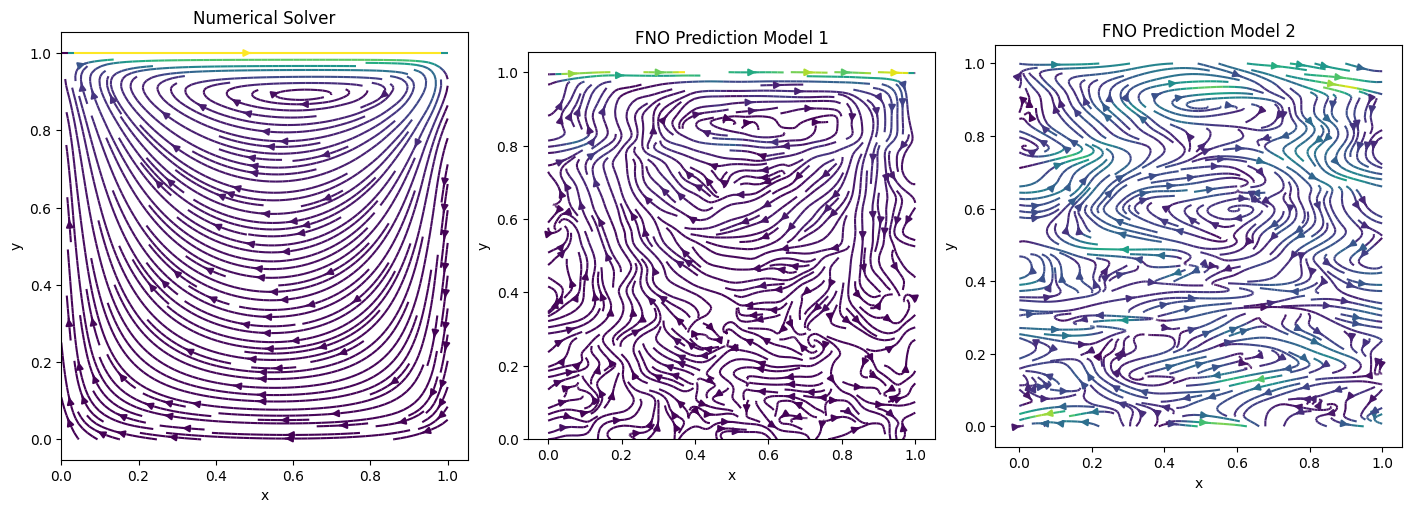

In [67]:
# ============================================================
# COMPARISON
# ============================================================

fig, ax = plt.subplots(
    1,
    3,
    figsize=(14,6),
    constrained_layout=True
)

# ---------------------------------
# Numerical
# ---------------------------------

speed = np.sqrt(
    u_true_mid.numpy()**2 +
    v_true_mid.numpy()**2
)

strm = ax[0].streamplot(
    x,
    y,
    u_true_mid.numpy().T,
    v_true_mid.numpy().T,
    color=speed.T,
    cmap="viridis",
    density=2,
)

ax[0].set_title("Numerical Solver")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[0].set_aspect("equal")

# ---------------------------------
# Prediction
# ---------------------------------

speed = np.sqrt(
    u_pred_mid1.numpy()**2 +
    v_pred_mid1.numpy()**2
)

ax[1].streamplot(
    x,
    y,
    u_pred_mid1.numpy().T,
    v_pred_mid1.numpy().T,
    color=speed.T,
    cmap="viridis",
    density=2,
)

ax[1].set_title("FNO Prediction Model 1")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].set_aspect("equal")


# ---------------------------------
# Prediction
# ---------------------------------

speed = np.sqrt(
    u_pred_mid2.numpy()**2 +
    v_pred_mid2.numpy()**2
)

ax[2].streamplot(
    x,
    y,
    u_pred_mid2.numpy().T,
    v_pred_mid2.numpy().T,
    color=speed.T,
    cmap="viridis",
    density=2,
)

ax[2].set_title("FNO Prediction Model 2")
ax[2].set_xlabel("x")
ax[2].set_ylabel("y")
ax[2].set_aspect("equal")


plt.show()